# Random Forest: adding ECG
Charis

I started with PPG, then added ECG to see whether it would bring the error down. This notebook shows example predictions and the results across the validation set.

### The inputs
Each prediction covers five seconds of PPG and ECG. The model uses 91 features, including pulse shape and heart rate. It combines the predictions from 200 trees.

ABP is the measured blood pressure used to check the answer. It is not an input to the model.

In [1]:
from pathlib import Path
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from demo_helpers import show_example

assets = Path('assets')
model = joblib.load(assets / 'rf_ecg.joblib')
print(f'Loaded RF model: {len(model.feature_names_in_)} input features')

Loaded RF model: 91 input features


### What the trees use
The trees get measurements from the signals, rather than the plots themselves. A few examples:

| Feature | What it describes |
|---|---|
| PPG heart rate | How often the pulse peaks occur |
| Pulse rise time | How quickly a pulse reaches its peak |
| ECG R–R variation | How much the spacing between heartbeats changes |

These are part of the 91 input features. They describe the signals; they do not directly measure blood pressure.

### How I trained it
I used 11,291 training windows from 1,308 recordings. The validation set has 857 windows from 100 recordings. Recordings and detected overlaps were kept together when splitting the data.

NeuroKit cleans the signals before feature extraction. Missing feature values are filled with medians learned from the training set. The model was trained beforehand; the demo loads it so we can focus on predictions.

In [2]:
forest = model.regressor_.named_steps['model']
settings = pd.Series({
    'Trees': forest.n_estimators,
    'Minimum samples per leaf': forest.min_samples_leaf,
    'Features considered per split': forest.max_features,
    'Maximum depth': 'Unlimited' if forest.max_depth is None else forest.max_depth,
}, name='RF settings')
display(settings.to_frame())

,RF settings
Trees,200
Minimum samples per leaf,5
Features considered per split,0.8
Maximum depth,Unlimited


### Try a recording
Run the cell below. Change `EXAMPLE` from 1 to 8 to try another window.

The first two plots show the inputs. The last plot shows the measured pressure for comparison.

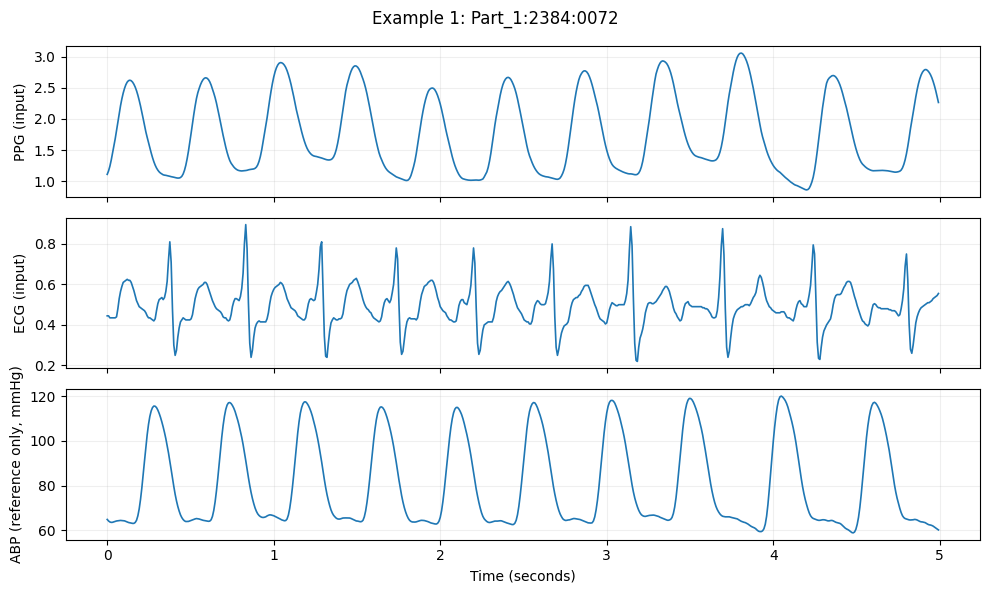

PPG template quality: 1.00; PPG peaks: 11; ECG R peaks: 10


,Target,Reference (mmHg),RF prediction (mmHg),Absolute error (mmHg)
0,Systolic,117.13,125.19,8.06
1,Diastolic,63.25,68.03,4.78


In [3]:
EXAMPLE = 1
display(show_example(EXAMPLE))

### One more example
Here is a window from another recording. Compare the errors with the first example: does the model get both pressures equally close?

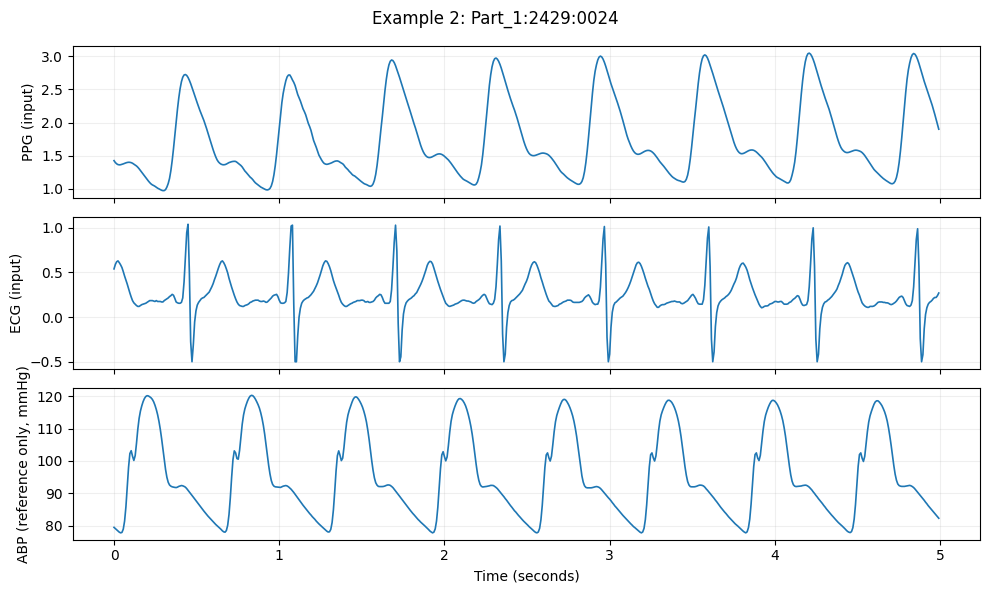

PPG template quality: 1.00; PPG peaks: 8; ECG R peaks: 8


,Target,Reference (mmHg),RF prediction (mmHg),Absolute error (mmHg)
0,Systolic,119.25,133.60,14.35
1,Diastolic,77.85,67.04,10.81


In [4]:
display(show_example(2))

### Did ECG help?
Here are the results on the same 857 validation windows from 100 recordings. MAE is the average absolute error; lower is better.

,Inputs,Pressure,MAE (mmHg),RMSE (mmHg),Within 10 mmHg (%)
0,PPG,Systolic,15.76,21.23,44.81
1,PPG,Diastolic,8.34,11.44,69.54
2,PPG + ECG,Systolic,15.03,20.43,49.01
3,PPG + ECG,Diastolic,7.63,10.92,77.83


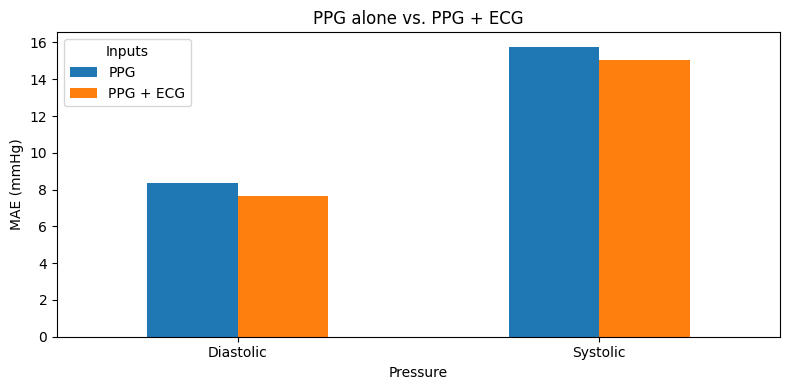

In [5]:
results = pd.read_csv(assets / 'validation_metrics.csv')
summary = results[['modality', 'target', 'mae_mmHg', 'rmse_mmHg', 'within_10_mmHg_pct']].copy()
summary.columns = ['Inputs', 'Pressure', 'MAE (mmHg)', 'RMSE (mmHg)', 'Within 10 mmHg (%)']
summary['Pressure'] = summary['Pressure'].map({'sbp': 'Systolic', 'dbp': 'Diastolic'})
display(summary.round(2).reset_index(drop=True))

comparison = summary.pivot(index='Pressure', columns='Inputs', values='MAE (mmHg)')
comparison.plot.bar(rot=0, ylabel='MAE (mmHg)', title='PPG alone vs. PPG + ECG', figsize=(8, 4))
plt.tight_layout()
plt.show()

### What changed
Adding ECG lowered systolic MAE from **15.76 to 15.03 mmHg** and diastolic MAE from **8.34 to 7.63 mmHg**. **77.8%** of the diastolic predictions were within 10 mmHg.

The improvement is useful, but systolic error is still fairly high.

For context, always predicting the training-set mean gave MAE of **18.70 / 10.02 mmHg**, so both RF versions improved on that baseline.

### What I would try next
I would compare the team’s models on the same recordings and labels before choosing one. Then we can check the final model on an untouched test set.

These are development validation results, not a final test. The eight examples were randomly selected without looking at their errors. Recordings and detected overlaps were grouped, but we do not have patient IDs. This is a research model.

### Data source
Kachuee, M., Kiani, M., Mohammadzade, H., & Shabany, M. (2015). [Cuff-Less Blood Pressure Estimation](https://doi.org/10.24432/C5B602). UCI Machine Learning Repository. The dataset is available under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

The bundled sample contains eight selected recordings and separate five-second ABP reference excerpts. Window labels and features follow this project's processing pipeline. See [DATA_SOURCE.md](DATA_SOURCE.md) for details.